## Compare RNNs, LSTMs, and GRUs with Tensorflow

### Part1 - Why SimpleRNN needs help !

#### step 1 - Import Tensorflow and Set Up

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
from datasets import load_dataset, load_from_disk

In [2]:
try:
    import tensorflow_datasets as tfds
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tensorflow_datasets'])
    import tensorflow_datasets as tfds

In [3]:
tf.keras.utils.set_random_seed(42)
tf.__version__

'2.22.0-rc0'

#### Step 2 - Review What SimpleRNN Did

###### TextVectorization -> Embedding -> SimpleRNN -> Dense

#### Step 3 - The Memory Problem

###### Long sequences make memory and learning harder for a basic RNN.
###### This is one reason LSTMs and GRUs were created.

#### Step 4 - What LSTMs and GRUs Add
###### LSTMs and GRUs are still sequence models.
###### They still read tokens in order
###### The difference is that they add better memory control

### Part 2 - Prepare the Movie Review Dataset
#### Step 5 - Load the IMDB Dataset

In [4]:
# Load from local disk (no internet needed)
dataset = load_from_disk("./imdb_stanfordnlp")

train_hf = dataset["train"].shuffle(seed=42).select(range(10000))
test_hf  = dataset["test"].shuffle(seed=42).select(range(5000))

train_data = tf.data.Dataset.from_tensor_slices((
        list(train_hf["text"]),
        list(train_hf["label"])
    ))
test_data  = tf.data.Dataset.from_tensor_slices((
        list(test_hf["text"]),
        list(test_hf["label"])
    ))

print(train_data)
print(test_data)

<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>
<_TensorSliceDataset element_spec=(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))>


#### Step 6 - Inspect a Few Review
###### Before we build model, we inspect the data.

In [5]:
for review, label in train_data.take(2):
    print("Review:")
    print(review.numpy().decode("utf-8")[:600], "...")
    print("Label: ", label.numpy())
    print("-" * 100)

Review:
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it's the language, o ...
Label:  1
----------------------------------------------------------------------------------------------------
Review:
This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids called "when you stub your toe on the moon" It reminds me of Sinatra's song High Hopes, it 

#### Step 7 - Create the TextVectorizer Layer

In [6]:
max_tokens = 10000
sequence_length = 150

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    output_sequence_length=sequence_length
)
train_text_only = train_data.map(lambda text, labels: text)
vectorizer.adapt(train_text_only.batch(1024))

vocab = vectorizer.get_vocabulary()
print(len(vocab))
print(vocab[:20])
print(vocab[-20:])

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step
10000
['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('br'), np.str_('was'), np.str_('as'), np.str_('with'), np.str_('for'), np.str_('but'), np.str_('movie')]
[np.str_('syrup'), np.str_('suspiciously'), np.str_('summarized'), np.str_('sullavan'), np.str_('sucking'), np.str_('sucker'), np.str_('successor'), np.str_('succeeding'), np.str_('suburbia'), np.str_('strain'), np.str_('stockwell'), np.str_('stifler'), np.str_('stepped'), np.str_('steamy'), np.str_('staden'), np.str_('stacy'), np.str_('squeamish'), np.str_('spitting'), np.str_('spins'), np.str_('spinning')]


### Step 8 - Check One Vectorized Review
##### Before we train any model, we should confirm that the vectorizer works.

In [7]:
for review, label in train_data.take(1):
    one_review = tf.expand_dims(review, axis=0)
    vectorized_review = vectorizer(one_review)
    print("Orig:")
    print(review.numpy().decode("utf-8")[:300], "...")
    print("Vectorized shape:", vectorized_review.shape)
    print("First 50 tokens IDs: ")
    print(vectorized_review[:50].numpy()[:50])

Orig:
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot  ...
Vectorized shape: (1, 150)
First 50 tokens IDs: 
[[  48    7   59 4381   31   32  203    1    3    1   18    2  191   12
   187   24  511  213   43 1081 2769    1  263    1    1  263  353    1
  1801   24  178  581    1  116   24  236   53 2400    1  263   53   39
  2240 1774   44   72   26    6 1478 4649    2  291  110    7  780    3
  9409   18   26    1   81   39    6 1672    6 1993    6    1   89   43
    42 2394  164  146  101   81  497    1  263  309   18   21    2   77
   539 7004   35 2866  309  213  267   30    2 1215   40    2 1154   18
    10  102   11  213    7   53  654   71  309   33    2   99    2  152
    24   62   50    3  164    2  113    7   22 3373   31   32   

### Step 9 - Create Training and Test Batches

##### Now we prepare batches
##### We use three common dataset operations:

* shuffle()
* batch()
* prefetch()

In [8]:
batch_size = 64

train_batches = (
    train_data
    .shuffle(10000, seed=42).batch(batch_size)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)
test_batches = (
    train_data
    .batch(batch_size)
    .prefetch(buffer_size=tf.data.AUTOTUNE)
)

for batch_review, batch_labels in train_batches.take(1):
    print("Batches review shape: ", batch_review.shape)
    print("Batch labels shape: ", batch_labels.shape)
    print("First 10 labels: ", batch_labels[:10].numpy())

Batches review shape:  (64,)
Batch labels shape:  (64,)
First 10 labels:  [0 0 0 1 1 0 1 1 1 0]


## Part 3 - Build Three Sequence Models
#### Step 10 - Create a Reusable Model Builder
##### We are going to compare  three models:

###### Embedding -> SimpleRNN -> Dense
###### Embedding -> LSTM -> Dense
###### Embedding -> GRU -> Dense

In [9]:
embedding_dim = 32
sequence_units = 32

def build_sequence_model(sequence_layer, model_name):
    model = tf.keras.Sequential([
        vectorizer,
        tf.keras.layers.Embedding(input_dim=max_tokens, output_dim=embedding_dim, mask_zero=True, name = f"{model_name}_embedding"),
        sequence_layer,
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    return model

In [10]:
simple_rnn_model= build_sequence_model(
    tf.keras.layers.SimpleRNN(sequence_units),
    model_name="simple_rnn"
)

simple_rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 150)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_embedding            │ ?                      │   0 (unbuilt) │
│ (Embedding)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
lstm_model = build_sequence_model(
    tf.keras.layers.LSTM(sequence_units),
    model_name="lstm"
)
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 150)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_embedding (Embedding)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
gru_model = build_sequence_model(
    tf.keras.layers.GRU(sequence_units),
    model_name="gru"
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (1, 150)               │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_embedding (Embedding)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Part 4 - Train and Compare the Models
#### Step 14 - Create a Helper Function for Training
###### Now we create a helper function that trains and evaluates a model.
###### This avoids repeating the same training code three times.

In [13]:
def train_and_evaluate(model, model_name, epochs=2):
    print(f"\nTraining {model_name}")
    print("=" * 60)

    history = model.fit(
        train_batches,
        validation_data=test_batches,
        epochs=epochs,
        verbose=1,
    )

    loss, accuracy = model.evaluate(test_batches, verbose=0)

    print(f"\n{model_name} test loss: {loss:.4f}")
    print(f"\n{model_name} test accuracy: {accuracy:.4f}")

    return {
        "name": model_name,
        "history": history,
        "loss": loss,
        "accuracy": accuracy
    }

#### Step 15 - Train the SimpleRNN

In [14]:
simple_rnn_results = train_and_evaluate(
    simple_rnn_model,
    model_name="SimpleRNN",
    epochs=2
)


Training SimpleRNN
Epoch 1/2


C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'simple_rnn' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.5413 - loss: 0.6881 - val_accuracy: 0.7083 - val_loss: 0.6241
Epoch 2/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.7716 - loss: 0.5135 - val_accuracy: 0.8521 - val_loss: 0.3281

SimpleRNN test loss: 0.3281

SimpleRNN test accuracy: 0.8521


#### Step 16 - Train the LSTM

In [15]:
lstm_results = train_and_evaluate(
    lstm_model,
    model_name="LSTM",
    epochs=2
)


Training LSTM
Epoch 1/2


C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step - accuracy: 0.6501 - loss: 0.6085 - val_accuracy: 0.8402 - val_loss: 0.4035
Epoch 2/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - accuracy: 0.8534 - loss: 0.3598 - val_accuracy: 0.9246 - val_loss: 0.2301

LSTM test loss: 0.2301

LSTM test accuracy: 0.9246


#### Step 16 - Train the GRU

In [16]:
gru_results = train_and_evaluate(
    gru_model,
    model_name="GRU",
    epochs=2
)


Training GRU
Epoch 1/2


C:\Users\OMID\Documents\PyEnv\PyEnv314\Lib\site-packages\keras\src\layers\layer.py:1092: UserWarning: Layer 'gru' (of type GRU) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 70ms/step - accuracy: 0.5994 - loss: 0.6507 - val_accuracy: 0.8379 - val_loss: 0.3990
Epoch 2/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.8391 - loss: 0.3720 - val_accuracy: 0.8826 - val_loss: 0.3401

GRU test loss: 0.3401

GRU test accuracy: 0.8826


In [17]:
results = [simple_rnn_results, lstm_results, gru_results]

print("Model comparison:")
for result in results:
    print(f"{result['name']:10s} | Loss: {result['loss']:.4f} | Accuracy: {result['accuracy']:.4f}")

Model comparison:
SimpleRNN  | Loss: 0.3281 | Accuracy: 0.8521
LSTM       | Loss: 0.2301 | Accuracy: 0.9246
GRU        | Loss: 0.3401 | Accuracy: 0.8826


#### Step 19 - Plot Validation Accuracy
##### Numbers in a table is useful, but plots help us see the training story.

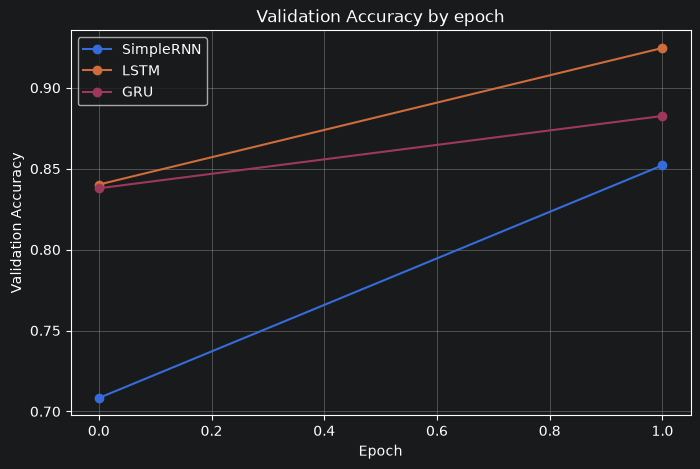

In [18]:
plt.figure(figsize=(8, 5))

for result in results:
    history = result["history"]
    plt.plot(history.history["val_accuracy"], marker="o", label=result["name"])

plt.title("Validation Accuracy by epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### Part 5 - Test the Models on Tricky Sentences
#### Step 20 - Create a Prediction Helper
##### Now we create a helper function to test custom sentences.

In [19]:
def predict_sentiment(model, texts, model_name):
    predictions = model.predict(tf.constant(texts), verbose=0)
    print(f"\n{model_name} prediction")
    print("-" * 60)

    for text, score in zip(texts, predictions):
        score = float(score[0])
        label = "positive" if score > 0.5 else "negative"
        print(f"{score:.3f} -> {label:8s} -> {text}")

### Step 21 - Predict With All Three Models
##### Now we compare predictions.

In [20]:
tricky_reviews = [
    "this movie was exellent and exciting",
    "this movie was boring and painfully slow",
    "not bad at all i actually enjoyed it",
    "the acting was good but the story was not good",
    "i wanted to like this movie but it was terrible",
]
predict_sentiment(simple_rnn_model, tricky_reviews, "SimpleRNN")
predict_sentiment(lstm_model, tricky_reviews, "LSTM")
predict_sentiment(gru_model, tricky_reviews, "GRU")


SimpleRNN prediction
------------------------------------------------------------
0.395 -> negative -> this movie was exellent and exciting
0.129 -> negative -> this movie was boring and painfully slow
0.200 -> negative -> not bad at all i actually enjoyed it
0.199 -> negative -> the acting was good but the story was not good
0.202 -> negative -> i wanted to like this movie but it was terrible

LSTM prediction
------------------------------------------------------------
0.562 -> positive -> this movie was exellent and exciting
0.221 -> negative -> this movie was boring and painfully slow
0.311 -> negative -> not bad at all i actually enjoyed it
0.577 -> positive -> the acting was good but the story was not good
0.252 -> negative -> i wanted to like this movie but it was terrible

GRU prediction
------------------------------------------------------------
0.524 -> positive -> this movie was exellent and exciting
0.152 -> negative -> this movie was boring and painfully slow
0.411 -> neg

### Step 21 - How to Read this Predictions
#### A score close to 1 means the model leans positive
#### A score close to 0 means the model leans negative